# **Predicting Residential Property Prices Using Multiple Linear Regression** 

### **Dataset:** Kaggle House Prices – Advanced Regression Techniques
### **Model:** Ordinary Least Squares (OLS) Multiple Linear Regression
### **Response variable:** SalePrice
### **Initial explanatory variables:** OverallQual, GrLivArea, GarageCars, TotalBsmtSF, YearBuilt, FullBath, LotArea

## **Objective**
### Fit an interpretable multiple linear regression model, examine the overall F-test and individual coefficient p-values, refine the model using training-set backward elimination, and assess predictability on a held-out 20% test sample using test $R^2$, RMSE, and MAE.

## **Dataset path** 
### The notebook uses the path supplied for the Kaggle environment:
### /kaggle/input/competitions/house-prices-advanced-regression-techniques/train.csv

### The Kaggle competition's test.csv does not contain SalePrice. Therefore, this analysis uses an 80:20 training/validation split of train.csv to evaluate predictive performance.

## **1. Install and import libraries**
 
### Section installs and imports the Python libraries required for data manipulation, visualization, statistical modelling, and predictive evaluation.

In [1]:
# Install required packages
!pip install pandas numpy matplotlib seaborn statsmodels scikit-learn

# Import libraries
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

warnings.filterwarnings("ignore", category=FutureWarning)

## **2. Load the Kaggle dataset**
 
### loads the House Prices dataset and identifies the response variable and explanatory variables.

### The dataset contains 1,460 residential property observations and 81 columns.

In [2]:
# Locate the dataset
KAGGLE_TRAIN_PATH = Path(
    "/kaggle/input/competitions/"
    "house-prices-advanced-regression-techniques/train.csv"
)

LOCAL_TRAIN_PATH = Path("train.csv")

if KAGGLE_TRAIN_PATH.exists():
    DATA_PATH = KAGGLE_TRAIN_PATH
elif LOCAL_TRAIN_PATH.exists():
    DATA_PATH = LOCAL_TRAIN_PATH
else:
    raise FileNotFoundError(
        "Attach the Kaggle competition training data."
    )

# Create output directory
OUT_DIR = (
    Path("/kaggle/working/regression_outputs")
    if Path("/kaggle/working").exists()
    else Path("regression_outputs")
)

OUT_DIR.mkdir(parents=True, exist_ok=True)

# Define response and explanatory variables
TARGET = "SalePrice"

FEATURES = [
    "OverallQual",
    "GrLivArea",
    "GarageCars",
    "TotalBsmtSF",
    "YearBuilt",
    "FullBath",
    "LotArea"
]

# Load dataset
df = pd.read_csv(DATA_PATH)

# Convert selected columns into numeric format
for col in FEATURES + [TARGET]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove observations without a response value
df = df.dropna(subset=[TARGET]).copy()

print("Dataset:", DATA_PATH)
print("Dataset shape:", df.shape)

print("\nSalePrice Descriptive Statistics")
print(df[TARGET].describe().round(2))

Dataset: /kaggle/input/competitions/house-prices-advanced-regression-techniques/train.csv
Dataset shape: (1460, 81)

SalePrice Descriptive Statistics
count      1460.0
mean     180921.2
std       79442.5
min       34900.0
25%      129975.0
50%      163000.0
75%      214000.0
max      755000.0
Name: SalePrice, dtype: float64


## **3. Exploratory data analysis**
 
### Examines the descriptive statistics, correlation between housing attributes and sale prices, and distribution of response variable.

### Correlation analysis helps to identify the strength and direction of linear association between each explanatory variable and the sale price. However, correlation does not establish causation.

### **3.1 Descriptive statistics**

In [3]:
print("DESCRIPTIVE STATISTICS")

print(
    df[FEATURES + [TARGET]]
    .describe()
    .T
    .round(2)
)

DESCRIPTIVE STATISTICS
              count       mean       std      min        25%       50%  \
OverallQual  1460.0       6.10      1.38      1.0       5.00       6.0   
GrLivArea    1460.0    1515.46    525.48    334.0    1129.50    1464.0   
GarageCars   1460.0       1.77      0.75      0.0       1.00       2.0   
TotalBsmtSF  1460.0    1057.43    438.71      0.0     795.75     991.5   
YearBuilt    1460.0    1971.27     30.20   1872.0    1954.00    1973.0   
FullBath     1460.0       1.57      0.55      0.0       1.00       2.0   
LotArea      1460.0   10516.83   9981.26   1300.0    7553.50    9478.5   
SalePrice    1460.0  180921.20  79442.50  34900.0  129975.00  163000.0   

                   75%       max  
OverallQual       7.00      10.0  
GrLivArea      1776.75    5642.0  
GarageCars        2.00       4.0  
TotalBsmtSF    1298.25    6110.0  
YearBuilt      2000.00    2010.0  
FullBath          2.00       3.0  
LotArea       11601.50  215245.0  
SalePrice    214000.00  755000

### **3.2 Correlation analysis**

In [4]:
# Calculate the correlation matrix
correlation = df[FEATURES + [TARGET]].corr(
    numeric_only=True
)

print("\nCORRELATION WITH SALEPRICE")

print(
    correlation[TARGET]
    .sort_values(ascending=False)
    .round(3)
)

# Export correlation matrix
correlation.to_csv(
    OUT_DIR / "correlation_matrix.csv"
)


CORRELATION WITH SALEPRICE
SalePrice      1.000
OverallQual    0.791
GrLivArea      0.709
GarageCars     0.640
TotalBsmtSF    0.614
FullBath       0.561
YearBuilt      0.523
LotArea        0.264
Name: SalePrice, dtype: float64


### **3.3 Correlation matrix visualization**

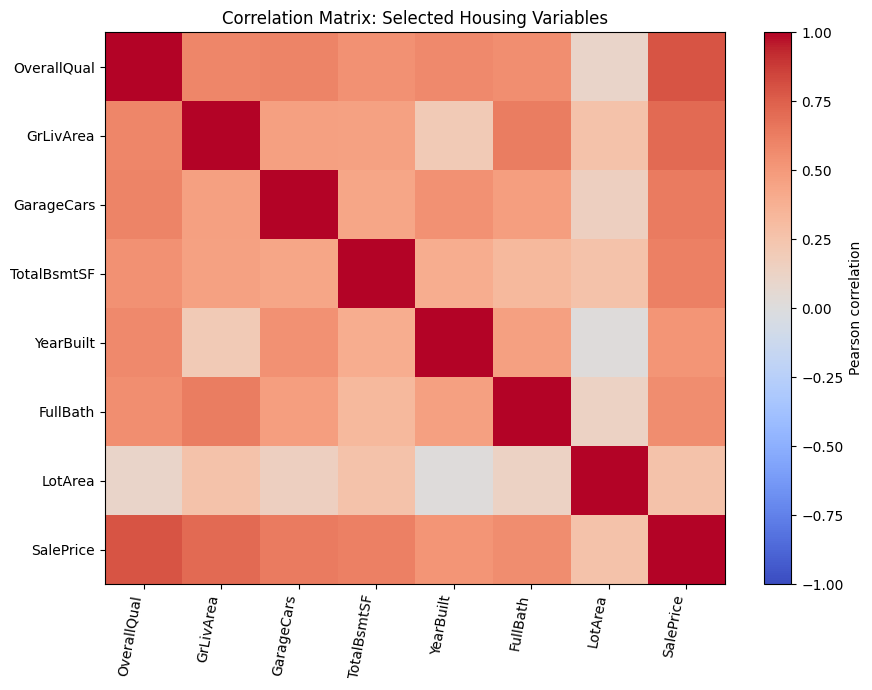

In [5]:
fig, ax = plt.subplots(figsize=(9, 7))

image = ax.imshow(
    correlation.values,
    aspect="auto",
    vmin=-1,
    vmax=1,
    cmap="coolwarm"
)

ax.set_xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=80,
    ha="right"
)

ax.set_yticks(
    range(len(correlation.index)),
    correlation.index
)

ax.set_title(
    "Correlation Matrix: Selected Housing Variables"
)

fig.colorbar(
    image,
    ax=ax,
    label="Pearson correlation"
)

fig.tight_layout()
plt.show()

### **3.4 SalePrice distribution**

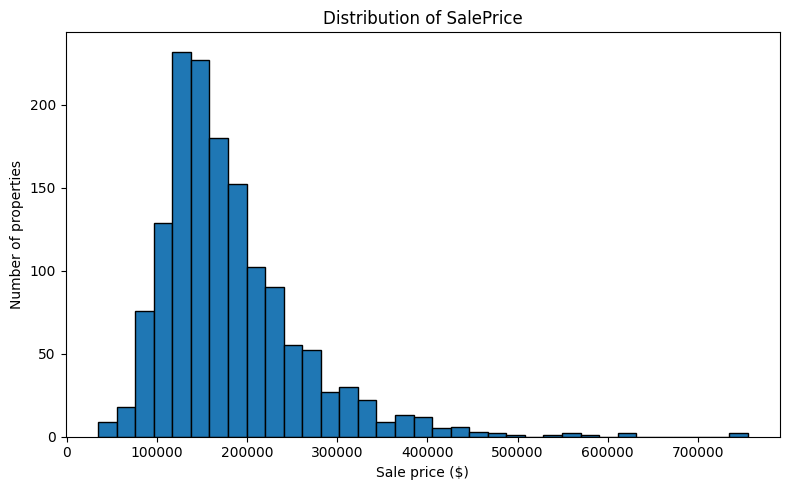

In [6]:
plt.figure(figsize=(8, 5))

plt.hist(
    df[TARGET],
    bins=35,
    edgecolor="black"
)

plt.title("Distribution of SalePrice")
plt.xlabel("Sale price ($)")
plt.ylabel("Number of properties")

plt.tight_layout()
plt.show()

## **4. Split the dataset and handle missing values**
### The dataset is divided into training and testing samples using an 80:20 split.
### * Training data: 80% of observations.
### * Testing data: 20% of observations.
### * Random state: 42.

### Missing predictor values are replaced using their respective training-set medians. The same medians are then applied to the test set to prevent data leakage.

In [7]:
# Separate explanatory and response variables
X = df[FEATURES].copy()
y = df[TARGET].copy()

# Split dataset into training and testing samples
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Calculate medians using training data only
medians = X_train.median(numeric_only=True)

# Handle missing values
X_train = X_train.fillna(medians)
X_test = X_test.fillna(medians)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

Training observations: 1168
Testing observations: 292


## **5. Develop the initial multiple linear regression model**
### An Ordinary Least Squares (OLS) multiple linear regression model is developed using all seven explanatory variables.

### The model estimates the relationship between residential property characteristics and their selling prices.

## **5.1 Define the OLS fitting function**

In [8]:
def fit_ols(X_part, y_part):

    X_design = sm.add_constant(
        X_part,
        has_constant="add"
    )

    return sm.OLS(y_part, X_design).fit()

## **5.2 Define the prediction equation function**
### This function automatically generates the regression equation using the estimated coefficients.

In [9]:
def equation(model, variables):

    terms = [
        f"{model.params['const']:.6f}"
    ]

    for var in variables:

        coef = model.params[var]

        sign = "+" if coef >= 0 else "-"

        terms.append(
            f" {sign} {abs(coef):.6f}*{var}"
        )

    return (
        "Predicted SalePrice = "
        + "".join(terms)
    )

## **5.3 Fit the initial regression model**

In [10]:
initial_model = fit_ols(
    X_train[FEATURES],
    y_train
)

# Display regression summary
print("\nINITIAL REGRESSION MODEL")
print(initial_model.summary())

# Display prediction equation
print("\nINITIAL MODEL EQUATION")
print(equation(initial_model, FEATURES))


INITIAL REGRESSION MODEL
                            OLS Regression Results                            
Dep. Variable:              SalePrice   R-squared:                       0.766
Model:                            OLS   Adj. R-squared:                  0.765
Method:                 Least Squares   F-statistic:                     542.6
Date:                Fri, 06 Nov 2026   Prob (F-statistic):               0.00
Time:                        10:40:14   Log-Likelihood:                -13954.
No. Observations:                1168   AIC:                         2.792e+04
Df Residuals:                    1160   BIC:                         2.797e+04
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const       -7.857e+05  

### **Actual initial regression equation**
\begin{aligned}
\widehat{SalePrice} =\;&-785738.213226\\
&+21332.894735(OverallQual)\\
&+48.686416(GrLivArea)\\
&+14673.280089(GarageCars)\\
&+20.777167(TotalBsmtSF)\\
&+362.801208(YearBuilt)\\
&-5018.191270(FullBath)\\
&+0.642367(LotArea)
\end{aligned}

## **5.4 Display exact coefficient estimates**

In [11]:
print("\nINITIAL MODEL COEFFICIENTS")

for variable, coefficient in initial_model.params.items():

    print(
        f"{variable}: {coefficient:.10f}"
    )


INITIAL MODEL COEFFICIENTS
const: -785738.2132260095
OverallQual: 21332.8947354783
GrLivArea: 48.6864155175
GarageCars: 14673.2800890520
TotalBsmtSF: 20.7771668951
YearBuilt: 362.8012076504
FullBath: -5018.1912703332
LotArea: 0.6423667357


## **5.5 Examine individual variable significance**
### The t-test and p-value are used to determine whether each explanatory variable is statistically significant at the 5% significance level.

In [12]:
ci = initial_model.conf_int()

initial_table = pd.DataFrame({
    "Coefficient": initial_model.params,
    "Std_Error": initial_model.bse,
    "t_statistic": initial_model.tvalues,
    "p_value": initial_model.pvalues,
    "CI_95_Lower": ci[0],
    "CI_95_Upper": ci[1]
})

initial_table["Decision_at_5_percent"] = [
    (
        "Intercept"
        if name == "const"
        else (
            "Significant"
            if initial_model.pvalues[name] < 0.05
            else "Not significant"
        )
    )
    for name in initial_table.index
]

print("\nINITIAL MODEL VARIABLE SIGNIFICANCE")

print(
    initial_table.round(4)
)

# Export coefficient table
initial_table.to_csv(
    OUT_DIR / "initial_coefficients.csv"
)


INITIAL MODEL VARIABLE SIGNIFICANCE
             Coefficient   Std_Error  t_statistic  p_value  CI_95_Lower  \
const       -785738.2132  97667.9382      -8.0450   0.0000 -977363.7964   
OverallQual   21332.8947   1262.3799      16.8990   0.0000   18856.0914   
GrLivArea        48.6864      3.3385      14.5831   0.0000      42.1362   
GarageCars    14673.2801   2008.1891       7.3067   0.0000   10733.1907   
TotalBsmtSF      20.7772      3.1691       6.5561   0.0000      14.5593   
YearBuilt       362.8012     51.4476       7.0519   0.0000     261.8604   
FullBath      -5018.1913   2908.1014      -1.7256   0.0847  -10723.9185   
LotArea           0.6424      0.1086       5.9146   0.0000       0.4293   

             CI_95_Upper Decision_at_5_percent  
const       -594112.6301             Intercept  
OverallQual   23809.6981           Significant  
GrLivArea        55.2367           Significant  
GarageCars    18613.3695           Significant  
TotalBsmtSF      26.9950           Signifi

## **5.6 Test the overall significance of the regression model**
### The overall F-test determines whether the explanatory variables jointly provide statistically significant information about SalePrice.

In [13]:
print(
    "\nOverall F-statistic:",
    initial_model.fvalue
)

print(
    "Overall F-test p-value:",
    initial_model.f_pvalue
)


Overall F-statistic: 542.5856965389802
Overall F-test p-value: 0.0


## **6. Refine the regression model using backward elimination**
### Backward elimination is used to remove statistically insignificant explanatory variables.

### The procedure starts with all seven predictors and repeatedly removes the predictor with the highest p-value when that p-value exceeds 0.05. 

### This process continues until all retained explanatory variables have p-values at or below 0.05.

In [14]:
alpha = 0.05

selected = FEATURES.copy()

elimination_log = []

while len(selected) > 1:

    candidate = fit_ols(
        X_train[selected],
        y_train
    )

    pvalues = candidate.pvalues.drop(
        labels=["const"],
        errors="ignore"
    )

    worst = pvalues.idxmax()

    worst_p = float(pvalues.max())

    if worst_p <= alpha:
        break

    elimination_log.append({
        "Removed_Feature": worst,
        "p_value_at_removal": worst_p
    })

    print(
        "Removing:",
        worst,
        "P-value:",
        worst_p
    )

    selected.remove(worst)

# Fit the final reduced model
reduced_model = fit_ols(
    X_train[selected],
    y_train
)

print("\nRETAINED PREDICTORS")
print(selected)

print("\nREDUCED REGRESSION MODEL")
print(reduced_model.summary())

print("\nREDUCED MODEL EQUATION")
print(equation(reduced_model, selected))

Removing: FullBath P-value: 0.08468747246103192

RETAINED PREDICTORS
['OverallQual', 'GrLivArea', 'GarageCars', 'TotalBsmtSF', 'YearBuilt', 'LotArea']

REDUCED REGRESSION MODEL
                            OLS Regression Results                            
Dep. Variable:              SalePrice   R-squared:                       0.765
Model:                            OLS   Adj. R-squared:                  0.764
Method:                 Least Squares   F-statistic:                     631.4
Date:                Fri, 06 Nov 2026   Prob (F-statistic):               0.00
Time:                        10:40:14   Log-Likelihood:                -13956.
No. Observations:                1168   AIC:                         2.793e+04
Df Residuals:                    1161   BIC:                         2.796e+04
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                  coef    std err

## **6.1 Modified regression equation**

### **The resulting reduced model is:**
\begin{aligned}
\widehat{SalePrice} =\;&-725446.139571\\
&+21232.435174(OverallQual)\\
&+45.718503(GrLivArea)\\
&+14497.483467(GarageCars)\\
&+21.575195(TotalBsmtSF)\\
&+330.513015(YearBuilt)\\
&+0.646758(LotArea)
\end{aligned}

## **6.2 Examine reduced model coefficients and significance**

In [15]:
# Display exact reduced model coefficients
print("\nREDUCED MODEL COEFFICIENTS")

for variable, coefficient in reduced_model.params.items():

    print(
        f"{variable}: {coefficient:.10f}"
    )

# Calculate confidence intervals
ci = reduced_model.conf_int()

reduced_table = pd.DataFrame({
    "Coefficient": reduced_model.params,
    "Std_Error": reduced_model.bse,
    "t_statistic": reduced_model.tvalues,
    "p_value": reduced_model.pvalues,
    "CI_95_Lower": ci[0],
    "CI_95_Upper": ci[1]
})

print("\nREDUCED MODEL VARIABLE SIGNIFICANCE")

print(
    reduced_table.round(4)
)

# Export reduced model results
reduced_table.to_csv(
    OUT_DIR / "reduced_coefficients.csv"
)

# Export backward elimination history
pd.DataFrame(elimination_log).to_csv(
    OUT_DIR / "backward_elimination_log.csv",
    index=False
)

# Overall significance
print(
    "\nReduced model F-statistic:",
    reduced_model.fvalue
)

print(
    "Reduced model F-test p-value:",
    reduced_model.f_pvalue
)


REDUCED MODEL COEFFICIENTS
const: -725446.1395714608
OverallQual: 21232.4351736233
GrLivArea: 45.7185027675
GarageCars: 14497.4834668688
TotalBsmtSF: 21.5751952833
YearBuilt: 330.5130151250
LotArea: 0.6467579025

REDUCED MODEL VARIABLE SIGNIFICANCE
             Coefficient   Std_Error  t_statistic  p_value  CI_95_Lower  \
const       -725446.1396  91281.9472      -7.9473      0.0 -904542.1762   
OverallQual   21232.4352   1262.1103      16.8230      0.0   18756.1629   
GrLivArea        45.7185      2.8638      15.9640      0.0      40.0996   
GarageCars    14497.4835   2007.3108       7.2223      0.0   10559.1209   
TotalBsmtSF      21.5752      3.1379       6.8758      0.0      15.4187   
YearBuilt       330.5130     47.9651       6.8907      0.0     236.4049   
LotArea           0.6468      0.1087       5.9516      0.0       0.4335   

             CI_95_Upper  
const       -546350.1029  
OverallQual   23708.7075  
GrLivArea        51.3374  
GarageCars    18435.8460  
TotalBsmtSF   

## **7. Evaluate the predictability of the regression models**
### The predictive performance of the initial and reduced models is evaluated using the held-out test dataset.

### The following metrics are considered:
 
* ### R²: Measures the proportion of variation in actual sale prices explained by the model on the test sample.
* ### RMSE: Measures the square root of the average squared prediction errors, expressed in dollars.
* ### MAE: Measures the average absolute prediction error, expressed in dollars.


### Higher test R² and lower RMSE and MAE generally indicate better predictive performance on the same test sample.

### **7.1 Define the model evaluation function**

In [16]:
def evaluate(
    model,
    train_x,
    test_x,
    train_y,
    test_y,
    name
):

    train_design = sm.add_constant(
        train_x,
        has_constant="add"
    )

    test_design = sm.add_constant(
        test_x,
        has_constant="add"
    )

    train_pred = model.predict(train_design)

    test_pred = model.predict(test_design)

    metrics = {

        "Model": name,

        "Predictor_Count": len(model.params) - 1,

        "Training_R2": r2_score(
            train_y,
            train_pred
        ),

        "Adjusted_Training_R2": model.rsquared_adj,

        "Test_R2": r2_score(
            test_y,
            test_pred
        ),

        "Test_RMSE_USD": np.sqrt(
            mean_squared_error(
                test_y,
                test_pred
            )
        ),

        "Test_MAE_USD": mean_absolute_error(
            test_y,
            test_pred
        )
    }

    return metrics, test_pred

## **7.2 Compare initial and reduced models**

In [17]:
initial_metrics, initial_pred = evaluate(
    initial_model,
    X_train[FEATURES],
    X_test[FEATURES],
    y_train,
    y_test,
    "Initial model"
)

reduced_metrics, reduced_pred = evaluate(
    reduced_model,
    X_train[selected],
    X_test[selected],
    y_train,
    y_test,
    "Reduced model"
)

comparison = pd.DataFrame([
    initial_metrics,
    reduced_metrics
])

print("\nMODEL PREDICTABILITY COMPARISON")

print(
    comparison.round(4).to_string(index=False)
)

# Export comparison results
comparison.to_csv(
    OUT_DIR / "model_comparison.csv",
    index=False
)


MODEL PREDICTABILITY COMPARISON
        Model  Predictor_Count  Training_R2  Adjusted_Training_R2  Test_R2  Test_RMSE_USD  Test_MAE_USD
Initial model                7       0.7660                0.7646   0.7957     39583.5463    24788.5223
Reduced model                6       0.7654                0.7642   0.7951     39646.3024    24816.4490


## **8. Actual versus predicted property prices**
### This visualization compares actual property prices with the prices predicted by both regression models.

### The dashed diagonal line represents perfect prediction. Points closer to this line indicate more accurate predictions.

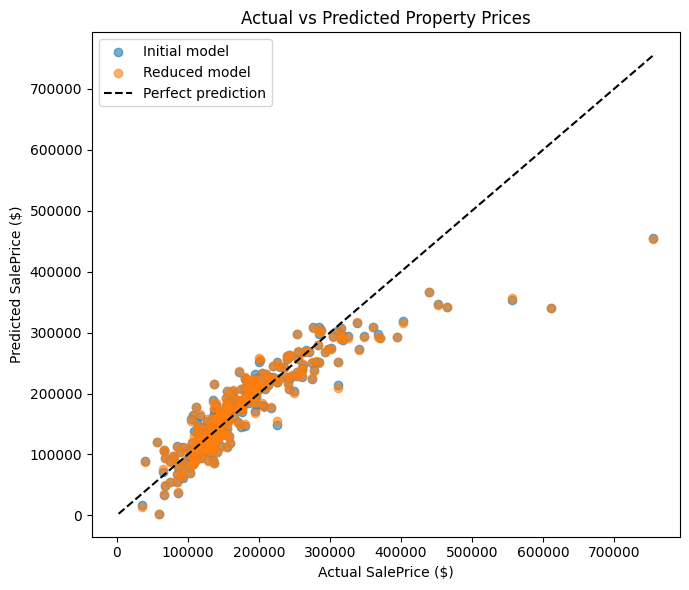

In [18]:
# Save test-set predictions
prediction_results = pd.DataFrame({

    "Actual_SalePrice": y_test,

    "Initial_Predicted_SalePrice": initial_pred,

    "Reduced_Predicted_SalePrice": reduced_pred

})

prediction_results.to_csv(
    OUT_DIR / "test_set_predictions.csv",
    index=False
)

# Plot actual versus predicted values
fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(
    y_test,
    initial_pred,
    alpha=0.6,
    label="Initial model"
)

ax.scatter(
    y_test,
    reduced_pred,
    alpha=0.6,
    label="Reduced model"
)

lo = min(
    y_test.min(),
    initial_pred.min(),
    reduced_pred.min()
)

hi = max(
    y_test.max(),
    initial_pred.max(),
    reduced_pred.max()
)

ax.plot(
    [lo, hi],
    [lo, hi],
    "k--",
    label="Perfect prediction"
)

ax.set_xlabel("Actual SalePrice ($)")
ax.set_ylabel("Predicted SalePrice ($)")

ax.set_title(
    "Actual vs Predicted Property Prices"
)

ax.legend()

plt.tight_layout()
plt.show()

## **9. Residual analysis of the reduced model**
### Residuals represent the difference between actual and predicted property prices.

## *Residual = Actual SalePrice - Predicted SalePrice*


### The residual plot helps identify possible patterns in prediction errors.

### Ideally, residuals should be randomly distributed around zero without a clear systematic pattern.

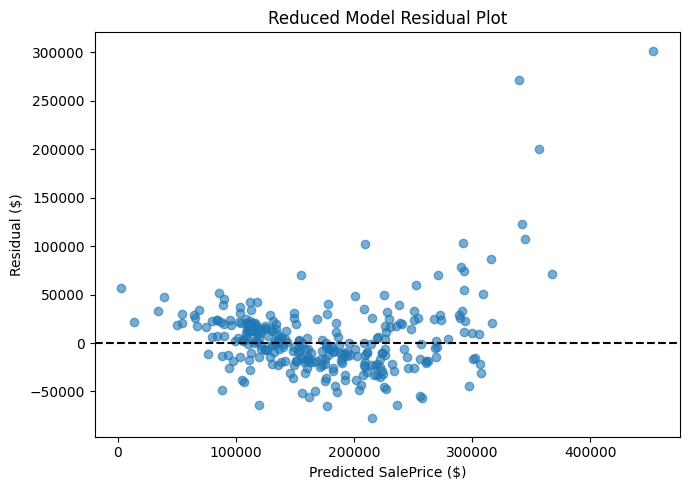

In [19]:
# Calculate residuals
residuals = y_test - reduced_pred

# Plot residuals
fig, ax = plt.subplots(figsize=(7, 5))

ax.scatter(
    reduced_pred,
    residuals,
    alpha=0.6
)

ax.axhline(
    0,
    color="black",
    linestyle="--"
)

ax.set_xlabel("Predicted SalePrice ($)")
ax.set_ylabel("Residual ($)")

ax.set_title(
    "Reduced Model Residual Plot"
)

plt.tight_layout()
plt.show()

## **10. Export the generated results**
### The following files are exported to the regression output directory for further analysis and report preparation.

In [20]:
print("\nGENERATED OUTPUT FILES")

for file in sorted(OUT_DIR.iterdir()):

    print(file.name)

print("\nOutput directory:", OUT_DIR)


GENERATED OUTPUT FILES
backward_elimination_log.csv
correlation_matrix.csv
initial_coefficients.csv
model_comparison.csv
reduced_coefficients.csv
test_set_predictions.csv

Output directory: /kaggle/working/regression_outputs
